# Week 4 Capstone Project
## Sales Analysis, Visualization & Sales Prediction
### Objective
The objective of this project is to analyze sales data, identify business insights, build a sales prediction model, and create an interactive Power BI dashboard.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from cycler import cycler
plt.rcParams["axes.prop_cycle"] = cycler(color = plt.cm.viridis(np.linspace(0, 1, 10)))

In [37]:
df = pd.read_excel("C:/Users/Urja Chauhan/Downloads/Sample data.xlsx")

## Data Understanding

In [38]:
df.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
1,Government,Germany,Paseo,NaN,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014
2,Government,Canada,Paseo,NaN,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,2013-11-01,11,November,2013
3,Government,Germany,Paseo,NaN,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
4,Government,Germany,Velo,NaN,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014


In [61]:
df.info()
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    object        
 1   Country              700 non-null    object        
 2   Product              700 non-null    object        
 3   Discount Band        647 non-null    object        
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9    Sales               700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 non-null    datetime64[ns]
 13  Month Number         700 non-null  

In [40]:
df.shape

(700, 16)

## Data Cleaning

In [41]:
df.isnull().sum()

Segment                 0
Country                 0
Product                 0
Discount Band          53
Units Sold              0
Manufacturing Price     0
Sale Price              0
Gross Sales             0
Discounts               0
 Sales                  0
COGS                    0
Profit                  0
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64

In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
df.describe()

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Year
count,700.000000,700.000000,700.000000,7.000000e+02,700.000000,7.000000e+02,700.000000,700.000000,700,700.000000,700.000000
mean,1608.294286,96.477143,118.428571,1.827594e+05,13150.354629,1.696091e+05,145475.211429,24133.860371,2014-04-28 21:36:00,7.900000,2013.750000
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,-40617.500000,2013-09-01 00:00:00,1.000000,2013.000000
25%,905.000000,5.000000,12.000000,1.739175e+04,800.320000,1.592800e+04,7490.000000,2805.960000,2013-12-24 06:00:00,5.750000,2013.750000
50%,1542.500000,10.000000,20.000000,3.798000e+04,2585.250000,3.554020e+04,22506.250000,9242.200000,2014-05-16 12:00:00,9.000000,2014.000000
75%,2229.125000,250.000000,300.000000,2.790250e+05,15956.343750,2.610775e+05,245607.500000,22662.000000,2014-09-08 12:00:00,10.250000,2014.000000
max,4492.500000,260.000000,350.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,2014-12-01 00:00:00,12.000000,2014.000000
std,867.427859,108.602612,136.775515,2.542623e+05,22962.928775,2.367263e+05,203865.506118,42760.626563,NaN,3.377321,0.433322


## Exploratory Data Analysis (EDA)

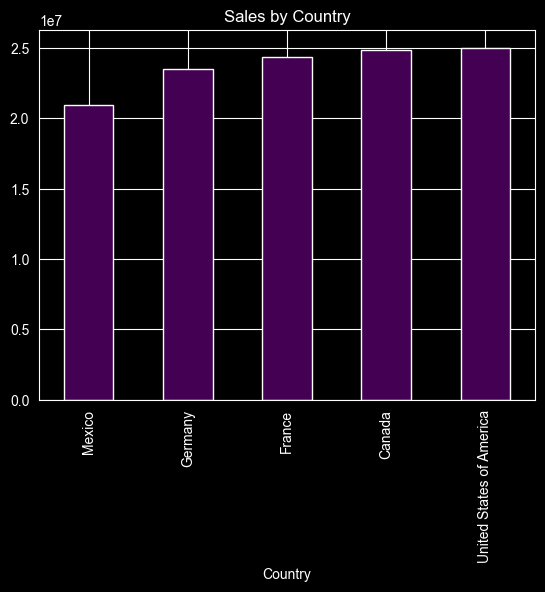

In [44]:
df.groupby("Country")[" Sales"].sum().sort_values().plot(kind="bar")
plt.title("Sales by Country")
plt.show()

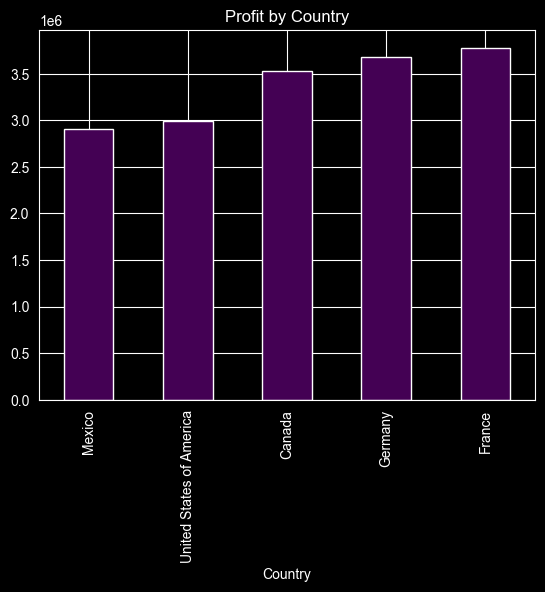

In [45]:
df.groupby("Country")["Profit"].sum().sort_values().plot(kind="bar")
plt.title("Profit by Country")
plt.show()

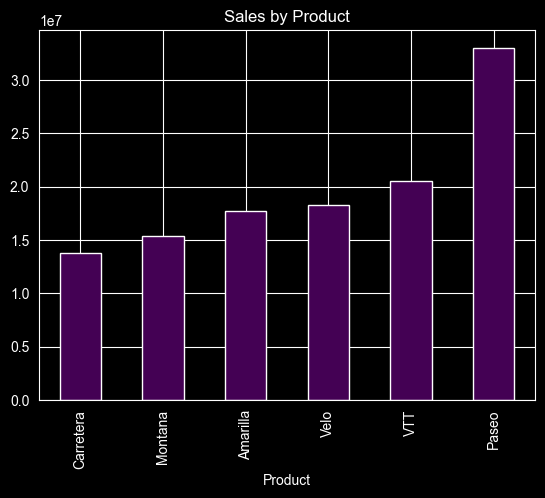

In [46]:
df.groupby("Product")[" Sales"].sum().sort_values().plot(kind="bar")
plt.title("Sales by Product")
plt.show()

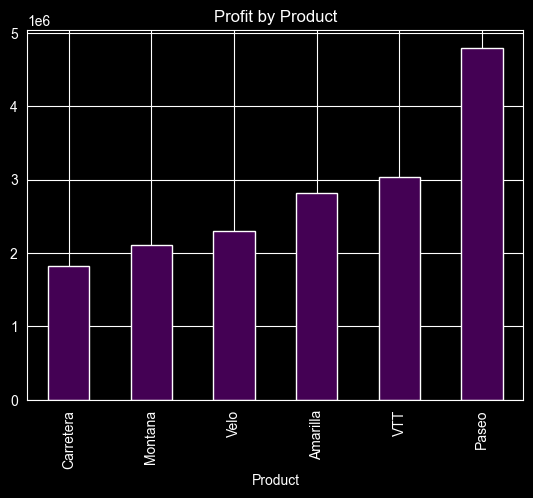

In [47]:
df.groupby("Product")["Profit"].sum().sort_values().plot(kind="bar")
plt.title("Profit by Product")
plt.show()

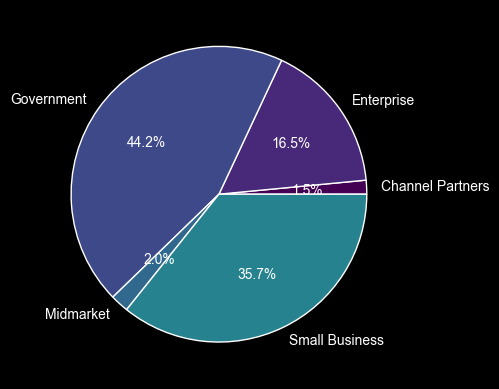

In [48]:
df.groupby("Segment")[" Sales"].sum().plot(kind="pie",autopct = "%1.1f%%")
plt.ylabel('')
plt.show()

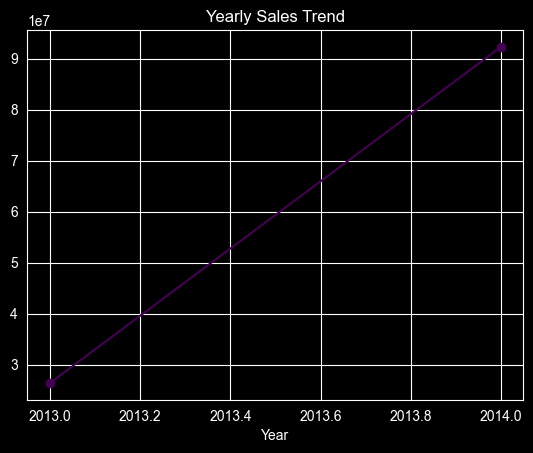

In [49]:
df.groupby("Year")[" Sales"].sum().plot(kind="line",marker="o")
plt.title("Yearly Sales Trend")
plt.show()

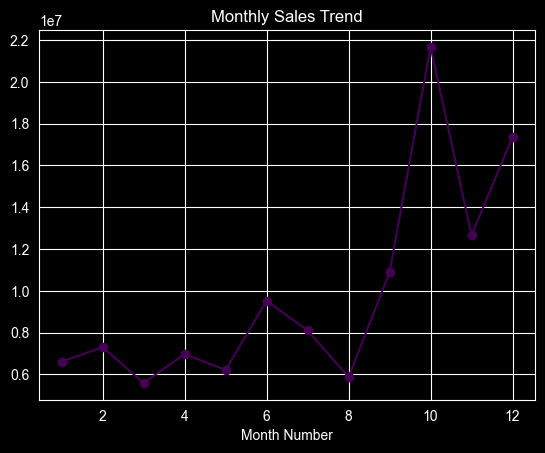

In [50]:
monthly = df.groupby("Month Number")[" Sales"].sum()

monthly.plot(kind="line",marker="o")
plt.title("Monthly Sales Trend")
plt.show()

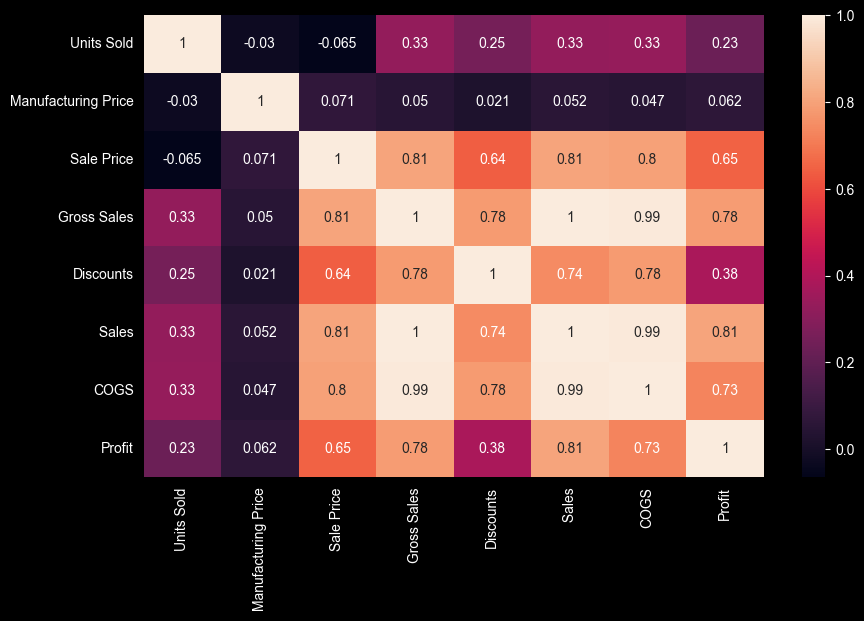

In [51]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df[["Units Sold",
        "Manufacturing Price",
        "Sale Price",
        "Gross Sales",
        "Discounts",
        " Sales",
        "COGS",
        "Profit"]].corr(),
    annot=True
           )
plt.show()

## Key Insights from EDA
- United States of America generated the highest sales.
- Paseo generated the highest sales.
- France generated the highest profit.
- Sales show noticeable variation across products and regions.
- Profit and Sales have a strong positive relationship.

## Sales Prediction Using Linear Regression

In [52]:
X = df[["Units Sold",
        "Manufacturing Price",
        "Sale Price",
        "Discounts",
        "COGS",
        "Profit"]]

In [53]:
Y = df[" Sales"]

In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [55]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0., 0.,-0.,-0., 1., 1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Units Sold','Manufacturing Price','Sale Price','Discounts','COGS', 'Profit']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.858e-10
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,6


In [56]:
Y_pred = model.predict(X_test)

In [57]:
from sklearn.metrics import r2_score
print("R2 Score:", r2_score(Y_test, Y_pred))

R2 Score: 1.0


### Model Performance
The Linear Regression model was trained to predict sales using historical business data.

The evaluation metrics indicate how accurately the model predicts future sales values.

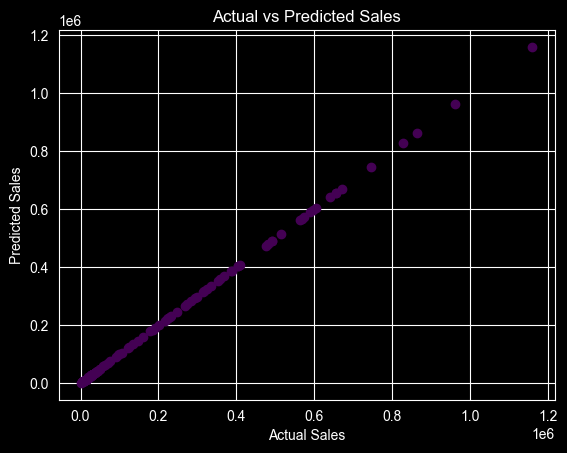

In [58]:
plt.scatter(Y_test, Y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

## Conclusion
The project successfully analyzed sales performance across countries, products, and segments. Visualizations helped identify key business trends, while the regression model demonstrated the ability  to predict sales using historical data. The findings can support better business decision-making and forecasting.

In [59]:
top_products = df.groupby("Product")[" Sales"].sum().sort_values(ascending = False)

print("Top 5 Products by Sales")
print(top_products.head())

Top 5 Products by Sales
Product
Paseo       3.301114e+07
VTT         2.051192e+07
Velo        1.825006e+07
Amarilla    1.774712e+07
Montana     1.539080e+07
Name:  Sales, dtype: float64


The table shows the top 5 products contributing the highest sales revenue.

In [60]:
top_countries = df.groupby("Country")["Profit"].sum().sort_values(ascending = False)

print("Top Countries by Profit")
print(top_countries.head())

Top Countries by Profit
Country
France                      3781020.780
Germany                     3680388.820
Canada                      3529228.885
United States of America    2995540.665
Mexico                      2907523.110
Name: Profit, dtype: float64


The table shows highlights the countries generating the highest profits.